In [3]:
# Student Name: Amelia Hamulewicz
# Student Number: C00296605
# Date: 06/10/2026

# Irish Property Prices: Rising Costs and Linear Regression
## How much have sale prices for houses risen since 2010, and can we predict future prices?
As a student living in Ireland, I chose to research the rising housing prices in Ireland, and what it could mean for buying a house in the future. 
In this portfolio, I will look at recorded house prices to see how they change overtime.


In my examples, I will use the median sale price for each year.

### Lets begin with the standard imports:

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

Now lets load the [Irish Housing Prices dataset](https://www.kaggle.com/datasets/fionnhughes/property-price-register) by FionnHughes, that I found on Kaggle.

I will mainly be using the **date_of_sale** and **price_eur columns** to investigate the rise in pricing.

In [2]:
house_data = pd.read_csv('property_price_register.csv', low_memory=False)
print('House data:', house_data.columns.tolist())

House data: ['date_of_sale', 'address', 'county', 'eircode', 'price_eur', 'not_full_market_price', 'vat_exclusive', 'description', 'property_size']


In [3]:
display(house_data.head()) # Show the first five rows

,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
0,2010-01-01,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,343000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
1,2010-01-03,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,185000.0,False,True,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,2010-01-04,"59 ormond keep, nenagh",Tipperary,NaN,128000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
3,2010-01-04,"66 Rory O'Connor Place, Arklow",Wicklow,NaN,145000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
4,2010-01-04,"78 Sundays Well Road, Cork",Cork,NaN,510000.0,False,False,Second-Hand Dwelling house /Apartment,NaN



The dataset has **807,936** rows and 9 columns. Each row is a recorded property sale.
This is a large dataset, but my examples use the median house price per year. This means the examples have far fewer values to work with than the original file.

In [4]:
print('Dataset size:', house_data.shape)

Dataset size: (807936, 9)


I converted the sale dates into dates Python can use and made sure prices are numbers. I then removed rows with a missing date or price.
I left out 2026 because it is an incomplete year in this file. I used 2010–2025 so that I am comparing full years only.

In [5]:
# Prepare the sale dates and prices
houses = house_data[['date_of_sale', 'price_eur']].dropna().copy()
houses['date_of_sale'] = pd.to_datetime(houses['date_of_sale'])
houses['year'] = houses['date_of_sale'].dt.year

print('Rows before cleaning:', house_data.shape[0])
print('Rows after removing missing values:', houses.shape[0])

# Exclude the incomplete year 2026
houses = houses[houses['year'] < 2026]
print('Rows in completed years:', houses.shape[0]) # 2010-2025 only
houses.head()

Rows before cleaning: 807936
Rows after removing missing values: 807936
Rows in completed years: 767334


,date_of_sale,price_eur,year
0,2010-01-01,343000.0,2010
1,2010-01-03,185000.0,2010
2,2010-01-04,128000.0,2010
3,2010-01-04,145000.0,2010
4,2010-01-04,510000.0,2010


No rows were removed for missing dates or prices. By removing the 2026 sales, we are now left with **767,334** rows.

## Calculating Sale Prices by Year



Number of yearly observations: 16


year
2010    202500.0
2011    170000.0
2012    150000.0
2013    140000.0
2014    150000.0
2015    162500.0
2016    183000.0
2017    210000.0
2018    226432.0
2019    235000.0
2020    240000.0
2021    256000.0
2022    285000.0
2023    302000.0
2024    327000.0
2025    352423.0
Name: price_eur, dtype: float64

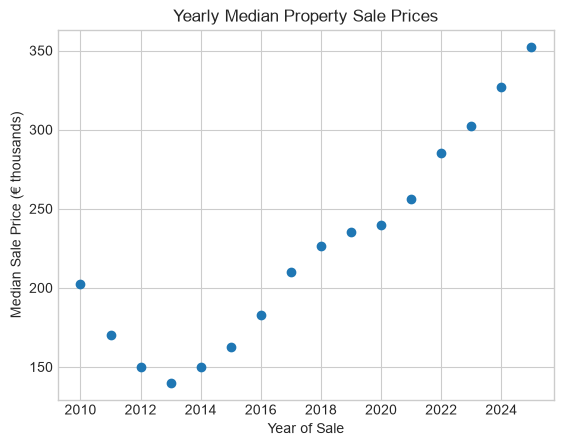

In [6]:
# Calculate the median recorded sale price for each completed year
yearly_prices = houses.groupby('year')['price_eur'].median()
years = yearly_prices.index.values
start_year = years.min()

# Count from the first year to keep polynomial inputs small
x = years - start_year
y = yearly_prices.values / 1000

print('Number of yearly observations:', len(x))
display(yearly_prices)

plt.scatter(years, y)
plt.xlabel('Year of Sale')
plt.ylabel('Median Sale Price (€ thousands)')
plt.title('Yearly Median Property Sale Prices')
plt.show()

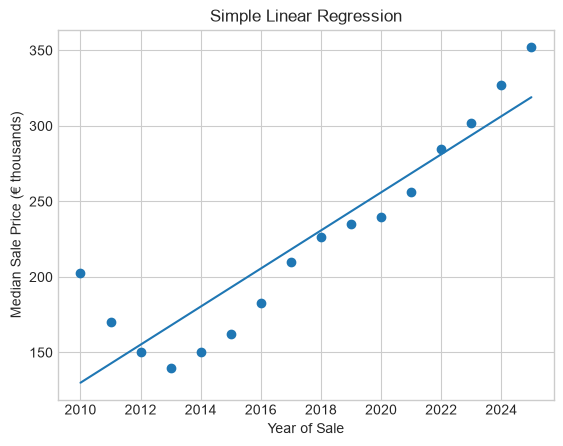

In [7]:
# Simple linear regression - same structure as the lab
model = LinearRegression(fit_intercept=True)
model.fit(x[:, np.newaxis], y)

xfit = np.linspace(x.min(), x.max(), 1000)
yfit = model.predict(xfit[:, np.newaxis])

plt.scatter(years, y)
plt.plot(xfit + start_year, yfit)
plt.xlabel('Year of Sale')
plt.ylabel('Median Sale Price (€ thousands)')
plt.title('Simple Linear Regression')
plt.show()

In [8]:
print('Model slope (€ thousands per year):', model.coef_[0])
print('Model intercept (€ thousands at the first year):', model.intercept_)

Model slope (€ thousands per year): 12.601142647058817
Model intercept (€ thousands at the first year): 129.98236764705888


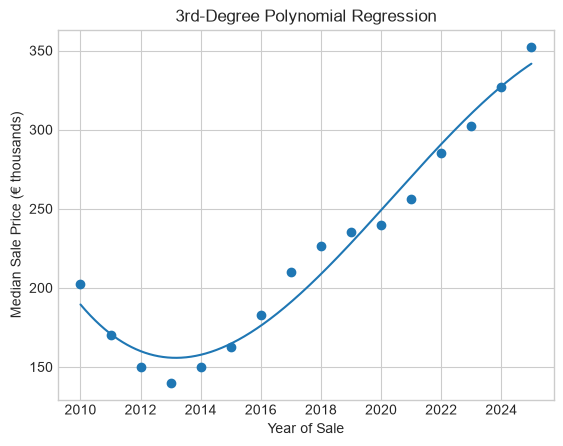

In [9]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Start with degree 3 because there are few yearly points
poly_model = make_pipeline(
    PolynomialFeatures(3),
    LinearRegression()
)

poly_model.fit(x[:, np.newaxis], y)
yfit = poly_model.predict(xfit[:, np.newaxis])

plt.scatter(years, y)
plt.plot(xfit + start_year, yfit)
plt.xlabel('Year of Sale')
plt.ylabel('Median Sale Price (€ thousands)')
plt.title('3rd-Degree Polynomial Regression')
plt.show()

In [10]:
from sklearn.base import BaseEstimator, TransformerMixin

class GaussianFeatures(BaseEstimator, TransformerMixin):
    """Uniformly spaced Gaussian features for one-dimensional input."""

    def __init__(self, N, width_factor=2.0):
        self.N = N
        self.width_factor = width_factor

    @staticmethod
    def _gauss_basis(x, y, width, axis=None):
        arg = (x - y) / width
        return np.exp(-0.5 * np.sum(arg ** 2, axis))

    def fit(self, X, y=None):
        self.centers_ = np.linspace(X.min(), X.max(), self.N)
        self.width_ = self.width_factor * (self.centers_[1] - self.centers_[0])
        return self

    def transform(self, X):
        return self._gauss_basis(
            X[:, :, np.newaxis],
            self.centers_,
            self.width_,
            axis=1
        )


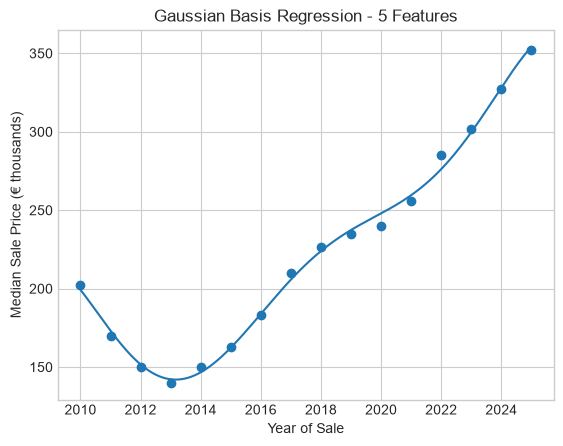

In [11]:
gauss_model = make_pipeline(
    GaussianFeatures(5),
    LinearRegression()
)

gauss_model.fit(x[:, np.newaxis], y)
yfit = gauss_model.predict(xfit[:, np.newaxis])

plt.scatter(years, y)
plt.plot(xfit + start_year, yfit)
plt.xlabel('Year of Sale')
plt.ylabel('Median Sale Price (€ thousands)')
plt.title('Gaussian Basis Regression - 5 Features')
plt.show()

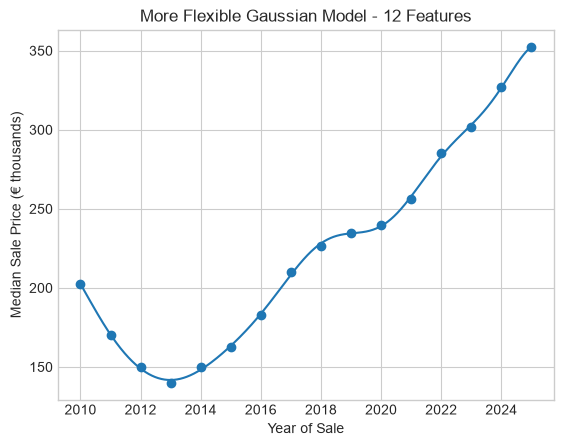

In [12]:
# Explore a more flexible fit using more Gaussian features
# A closer fit alone does not establish better predictions
flexible_model = make_pipeline(
    GaussianFeatures(12),
    LinearRegression()
)

flexible_model.fit(x[:, np.newaxis], y)

plt.scatter(years, y)
plt.plot(xfit + start_year, flexible_model.predict(xfit[:, np.newaxis]))
plt.xlabel('Year of Sale')
plt.ylabel('Median Sale Price (€ thousands)')
plt.title('More Flexible Gaussian Model - 12 Features')
plt.show()

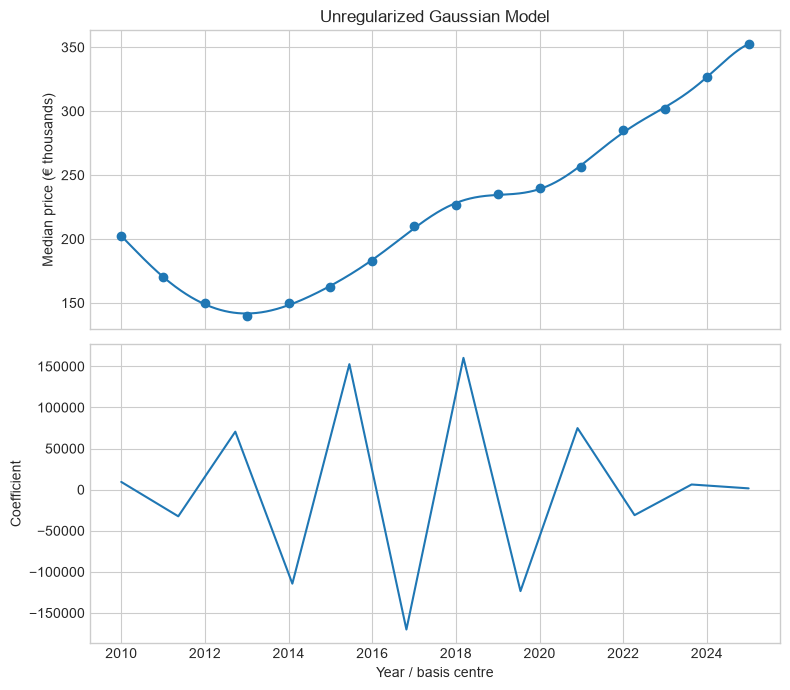

In [13]:
# Adapted from the lab: show the fit and its coefficients
def basis_plot(model, title=None):
    fig, ax = plt.subplots(2, sharex=True, figsize=(8, 7))
    model.fit(x[:, np.newaxis], y)

    ax[0].scatter(years, y)
    ax[0].plot(xfit + start_year, model.predict(xfit[:, np.newaxis]))
    ax[0].set(ylabel='Median price (€ thousands)')

    if title:
        ax[0].set_title(title)

    ax[1].plot(
        model.steps[0][1].centers_ + start_year,
        model.steps[1][1].coef_
    )
    ax[1].set(xlabel='Year / basis centre', ylabel='Coefficient')
    plt.tight_layout()
    plt.show()

basis_plot(flexible_model, 'Unregularized Gaussian Model')

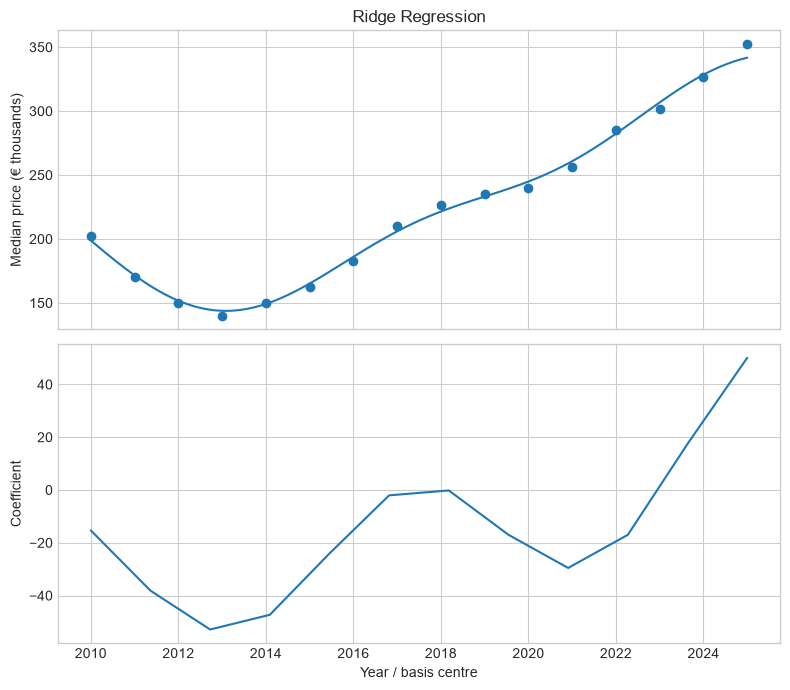

In [14]:
from sklearn.linear_model import Ridge

ridge_model = make_pipeline(
    GaussianFeatures(12),
    Ridge(alpha=0.1)
)

basis_plot(ridge_model, title='Ridge Regression')

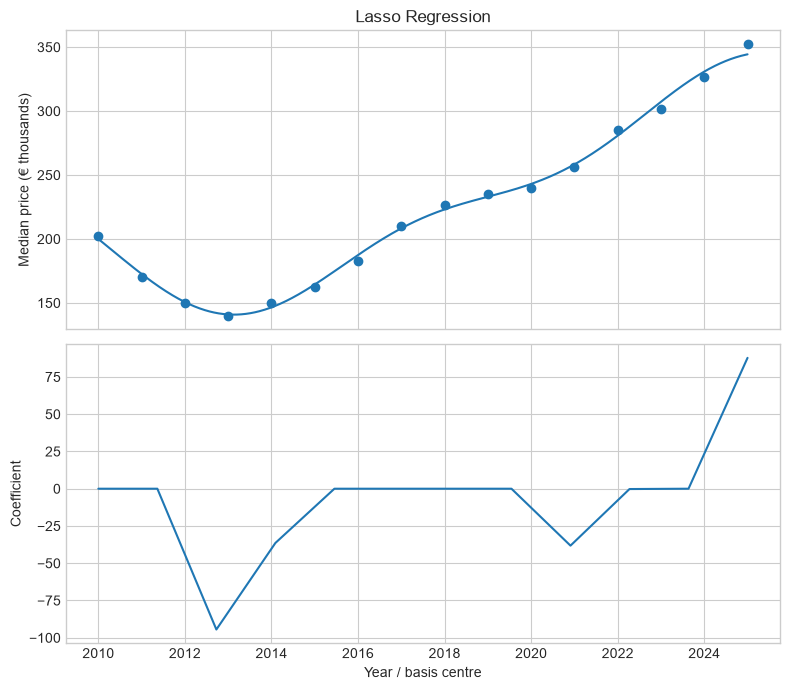

In [15]:
from sklearn.linear_model import Lasso

lasso_model = make_pipeline(
    GaussianFeatures(12),
    Lasso(alpha=0.1, max_iter=10000)
)

basis_plot(lasso_model, title='Lasso Regression')

# These alpha values are starting values, not proven best settings.
# Prices are in thousands of euros, so the lab's alpha may behave differently.

Training years: [2010 2011 2012 2013 2014 2015 2016 2017 2018 2019 2020 2021 2022]
Test years: [2023 2024 2025]


,Actual,Linear,Polynomial
Year,,,
2023,302.00,268.89,269.21
2024,327.00,278.62,255.63
2025,352.42,288.35,229.56


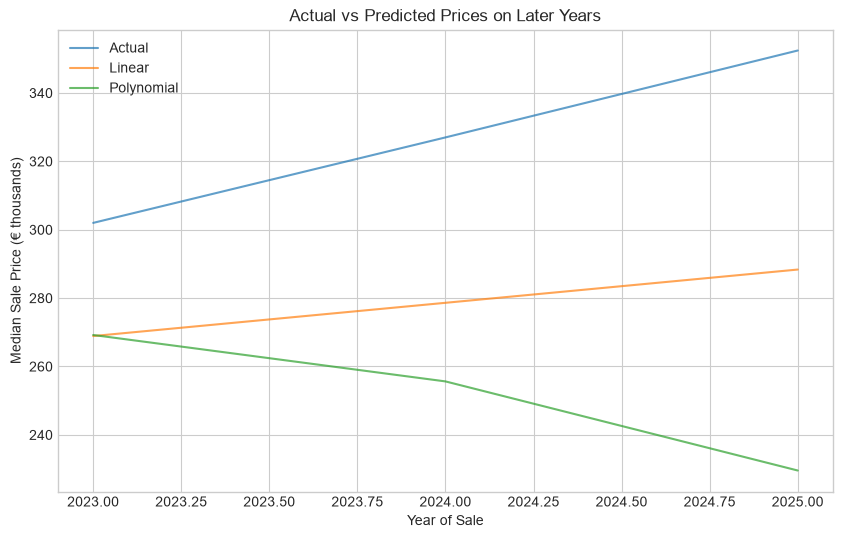

In [16]:
# Test on the last three completed years
# Fit fresh models using only earlier years
xtrain = x[:-3]
ytrain = y[:-3]
xtest = x[-3:]
ytest = y[-3:]

print('Training years:', years[:-3])
print('Test years:', years[-3:])

linear_test_model = LinearRegression()
linear_test_model.fit(xtrain[:, np.newaxis], ytrain)

poly_test_model = make_pipeline(PolynomialFeatures(3), LinearRegression())
poly_test_model.fit(xtrain[:, np.newaxis], ytrain)

results = pd.DataFrame({
    'Year': years[-3:],
    'Actual': ytest,
    'Linear': linear_test_model.predict(xtest[:, np.newaxis]),
    'Polynomial': poly_test_model.predict(xtest[:, np.newaxis])
}).set_index('Year')

display(results.round(2))
results.plot(alpha=0.7, figsize=(10, 6))
plt.xlabel('Year of Sale')
plt.ylabel('Median Sale Price (€ thousands)')
plt.title('Actual vs Predicted Prices on Later Years')
plt.show()

In [17]:
# Average size of the mistakes on the three test years
linear_error = np.mean(np.abs(results['Actual'] - results['Linear']))
poly_error = np.mean(np.abs(results['Actual'] - results['Polynomial']))
average_error = np.mean(np.abs(ytest - np.mean(ytrain)))

comparison = pd.DataFrame({
    'Method': ['Training average', 'Linear regression', 'Polynomial degree 3'],
    'Average test error (€ thousands)': [
        average_error, linear_error, poly_error
    ]
})
display(comparison.round(2))

# The first graphs show fitted patterns, not unseen-data accuracy.
# The test covers only three years; results may vary with another period.
# Annual medians can change when the mix of properties sold changes.
# The intercept refers to the first year, because x starts at zero.
# Check market-price and VAT flags before interpreting market-wide trends.
# GaussianFeatures and basis_plot are adapted from the supplied course lab.
# Dataset: https://www.kaggle.com/datasets/fionnhughes/property-price-register

,Method,Average test error (€ thousands)
0,Training average,126.34
1,Linear regression,48.52
2,Polynomial degree 3,75.67
